# EDA: Cirrhosis Patient Survival Prediction

**Задача.** По данным первого обследования предсказать, чем закончится наблюдение за пациентом (`Status`): `C` — жив к концу наблюдения, `CL` — трансплантация печени, `D` — смерть. Это многоклассовая классификация, одна строка — один пациент.

**Данные.** Kaggle Playground Series S3E26: `train` — 7905 строк с исходом, `test` — 5271 строка без него. Данные синтетические, сгенерированы по мотивам датасета UCI Cirrhosis: 418 пациентов клиники Мэйо, 1974–1984 ([DOI 10.24432/C5R02G](https://doi.org/10.24432/C5R02G), лицензия CC BY 4.0).

**Как читать.** Каждый блок устроен одинаково: что проверяем → код → короткий вывод. Общие выводы и что они значат для модели — в разделе 9.

## Описание столбцов

В наборе 20 столбцов: идентификатор, длительность наблюдения, целевая переменная и 17 клинических признаков.

### Идентификатор и целевые показатели
* **`id`** — порядковый номер строки.
* **`N_Days`** — количество дней от регистрации пациента до самого раннего из трёх событий: смерти, трансплантации печени или окончания анализа (июль 1986 года).
* **`Status`** — итоговый статус пациента (целевая переменная):
  * `C` *(censored)* — пациент был жив на момент окончания наблюдения;
  * `CL` *(censored due to liver tx)* — жив благодаря трансплантации печени;
  * `D` *(death)* — летальный исход.

### Демография и лечение
* **`Drug`** — назначенный препарат: `D-penicillamine` (Д-пеницилламин) или `Placebo` (плацебо).
* **`Age`** — возраст пациента в **днях**.
* **`Sex`** — пол пациента: `M` (мужской) или `F` (женский).

### Клинические симптомы (осмотр врача)
* **`Ascites`** — асцит (скопление свободной жидкости в брюшной полости): `N` (нет) или `Y` (да).
* **`Hepatomegaly`** — гепатомегалия (увеличение печени): `N` или `Y`.
* **`Spiders`** — сосудистые «звёздочки» (телеангиэктазии) на коже: `N` или `Y`.
* **`Edema`** — периферические отёки:
  * `N` — отёков нет, диуретики не принимаются;
  * `S` — отёки есть без диуретиков или сняты ими;
  * `Y` — отёки сохраняются даже на фоне диуретиков.

### Лабораторные анализы крови и тяжесть болезни
* **`Bilirubin`** — сывороточный билирубин (мг/дл), показатель желтухи и способности печени выводить желчь.
* **`Cholesterol`** — холестерин в сыворотке (мг/дл).
* **`Albumin`** — альбумин в сыворотке (г/дл), белок, который синтезирует печень.
* **`Copper`** — медь в суточной моче (мкг/день).
* **`Alk_Phos`** — щелочная фосфатаза (Ед/л), фермент, указывающий на застой желчи.
* **`SGOT`** — АСТ, аспартатаминотрансфераза (Ед/мл), отражает повреждение клеток печени.
* **`Tryglicerides`** — триглицериды (мг/дл); в данных столбец назван с опечаткой.
* **`Platelets`** — тромбоциты (тыс./мм³).
* **`Prothrombin`** — протромбиновое время (с), показатель свёртываемости крови.
* **`Stage`** — гистологическая стадия по биопсии, от `1` до `4` (4 — самая тяжёлая).

## 1. Загрузка и первичный осмотр

### 1.1 Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

### 1.2 Загрузка данных

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("train:", train.shape)
print("test: ", test.shape)

train: (7905, 20)
test:  (5271, 19)


### 1.3 Первый взгляд

In [3]:
train.head()

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


### 1.4 Структура и типы

In [4]:
info = pd.DataFrame({
    "тип": train.dtypes.astype(str),
    "уникальных": train.nunique(),
    "пропусков": train.isna().sum(),
})
info

,тип,уникальных,пропусков
id,int64,7905,0
N_Days,int64,461,0
Drug,str,2,0
Age,int64,391,0
Sex,str,2,0
Ascites,str,2,0
Hepatomegaly,str,2,0
Spiders,str,2,0
Edema,str,3,0
Bilirubin,float64,111,0


**Вывод:**
- 20 колонок: `id`, `Status`, 11 числовых показателей и 7 категориальных (вместе со `Stage`).
- `Age` записан в днях (21532 дня ≈ 59 лет) — перед моделью переведём в годы.
- `Stage` хранится дробным числом (3.0), хотя по смыслу это порядковая категория 1–4.
- У `Edema` три уровня: N, S, Y.

### 1.5 Пропуски и дубликаты

In [5]:
print("Пропусков всего:", train.isna().sum().sum())
print("Полных дублей без id:", train.drop(columns="id").duplicated().sum())
print("id в train:", train["id"].min(), "…", train["id"].max())
print("id в test: ", test["id"].min(), "…", test["id"].max())
print("Общих id:", len(set(train["id"]) & set(test["id"])))

Пропусков всего: 0
Полных дублей без id: 0
id в train: 0 … 7904
id в test:  7905 … 13175
Общих id: 0


**Вывод:**
- Пропусков и полных дублей нет. В исходном UCI пропуски были (Cholesterol, Tryglicerides, Copper, Alk_Phos) — в синтетике их уже заполнили, поэтому проверять по ним нечего.
- `id` идут подряд: train — 0…7904, test — 7905…13175. Набор разрезан по порядку строк, а не случайно; не дало ли это перекоса — проверяем в разделе 8.
- `id` — номер строки, в модель не идёт.

## 2. Первичная статистика

### 2.1 Категориальные признаки: значения и частоты

In [6]:
cat_cols = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]
for col in cat_cols:
    print(f"{col:13s}", train[col].value_counts().to_dict())

Drug          {'Placebo': 4010, 'D-penicillamine': 3895}
Sex           {'F': 7336, 'M': 569}
Ascites       {'N': 7525, 'Y': 380}
Hepatomegaly  {'Y': 4042, 'N': 3863}
Spiders       {'N': 5966, 'Y': 1939}
Edema         {'N': 7161, 'S': 399, 'Y': 345}
Stage         {3.0: 3153, 4.0: 2703, 2.0: 1652, 1.0: 397}


**Вывод:**
- Почти все признаки бинарные, но доли очень разные: мужчин 7.2 % (569 человек), асцит у 4.8 % (380), гепатомегалия — почти у половины.
- Женщин 93 %, а в исходном UCI было около 75 % — это свойство генератора. `Sex` почти константа и мало что даст модели.
- По редким уровням (M, Ascites=Y) дальше смотрим не только долю, но и число людей: на маленьких группах легко получить случайный вывод.

### 2.2 Числовые признаки

In [7]:
num_cols = ["N_Days", "Age", "Bilirubin", "Cholesterol", "Albumin", "Copper",
            "Alk_Phos", "SGOT", "Tryglicerides", "Platelets", "Prothrombin"]

train[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
N_Days,7905.0,2030.17,1094.23,41.00,1230.00,1831.00,2689.00,4795.00
Age,7905.0,18373.15,3679.96,9598.00,15574.00,18713.00,20684.00,28650.00
Bilirubin,7905.0,2.59,3.81,0.30,0.70,1.10,3.00,28.00
Cholesterol,7905.0,350.56,195.38,120.00,248.00,298.00,390.00,1775.00
Albumin,7905.0,3.55,0.35,1.96,3.35,3.58,3.77,4.64
Copper,7905.0,83.90,75.90,4.00,39.00,63.00,102.00,588.00
Alk_Phos,7905.0,1816.75,1903.75,289.00,834.00,1181.00,1857.00,13862.40
SGOT,7905.0,114.60,48.79,26.35,75.95,108.50,137.95,457.25
Tryglicerides,7905.0,115.34,52.53,33.00,84.00,104.00,139.00,598.00
Platelets,7905.0,265.23,87.47,62.00,211.00,265.00,316.00,563.00


**Вывод:** где есть длинный хвост, среднее заметно больше медианы: Bilirubin — 2.59 против 1.1, Cholesterol — 350.6 против 298, Alk_Phos — 1816.7 против 1181. У Albumin хвост короткий: медиана 3.58, максимум 4.64.

### 2.3 Асимметрия

Коэффициент асимметрии (skew) показывает, насколько вытянут хвост. Признаки с `|skew| > 1` — кандидаты на логарифмирование (`np.log1p`).

In [8]:
skew = train[num_cols].skew().sort_values(ascending=False)
skew.round(2).to_frame("асимметрия")

,асимметрия
Cholesterol,3.68
Bilirubin,3.34
Alk_Phos,3.20
Copper,2.70
Tryglicerides,2.63
SGOT,1.53
Prothrombin,1.29
N_Days,0.45
Platelets,0.42
Age,0.08


**Вывод:**
- Сильный правый хвост: Cholesterol 3.68, Bilirubin 3.34, Alk_Phos 3.20, Copper 2.70, Tryglicerides 2.63, SGOT 1.53 → для этих шести берём `log1p`.
- Prothrombin (1.29) оставляем как есть: значения лежат в узком диапазоне 9–18 с, и логарифм почти ничего не меняет (4.2).
- Albumin (−0.56), Age, N_Days и Platelets почти симметричны — без преобразований.

## 3. Приведение признаков к рабочему виду

### 3.1 Клинические диапазоны

Проверяем, что значения физиологически возможны: нет нулей, отрицательных чисел и «заглушек» вроде 999.

In [9]:
ranges = {
    "Bilirubin": (0.1, 30),
    "Cholesterol": (100, 2000),
    "Albumin": (1.5, 5.0),
    "Copper": (0, 600),
    "Alk_Phos": (200, 15000),
    "SGOT": (20, 500),
    "Tryglicerides": (30, 600),
    "Platelets": (50, 600),
    "Prothrombin": (8, 20),
}
for c, (lo, hi) in ranges.items():
    bad = ((train[c] < lo) | (train[c] > hi)).sum()
    print(f"{c:15s} | реальный [{train[c].min():.2f}, {train[c].max():.2f}] | вне диапазона: {bad}")

Bilirubin       | реальный [0.30, 28.00] | вне диапазона: 0
Cholesterol     | реальный [120.00, 1775.00] | вне диапазона: 0
Albumin         | реальный [1.96, 4.64] | вне диапазона: 0
Copper          | реальный [4.00, 588.00] | вне диапазона: 0
Alk_Phos        | реальный [289.00, 13862.40] | вне диапазона: 0
SGOT            | реальный [26.35, 457.25] | вне диапазона: 0
Tryglicerides   | реальный [33.00, 598.00] | вне диапазона: 0
Platelets       | реальный [62.00, 563.00] | вне диапазона: 0
Prothrombin     | реальный [9.00, 18.00] | вне диапазона: 0


**Вывод:** все значения в правдоподобных границах, ошибок ввода не видно — чистить нечего.

### 3.2 Повторяющиеся профили

Полных дублей нет, но если убрать `id`, `Status` и `N_Days`, часть строк может совпасть по всем 17 признакам. При кросс-валидации такие строки должны попадать в один фолд, иначе модель проверяют на копии того, что она уже видела.

In [10]:
feature_cols = train.columns.drop(["id", "Status", "N_Days"])
in_dup = train[feature_cols].duplicated(keep=False)

print("Повторных профилей (лишних копий):", train[feature_cols].duplicated().sum())
print("Строк, участвующих в повторах:   ", in_dup.sum())
train.loc[in_dup].sort_values(list(feature_cols))[["id", "Status", "N_Days", "Age", "Bilirubin", "Albumin", "Stage"]]

Повторных профилей (лишних копий): 5
Строк, участвующих в повторах:    10


,id,Status,N_Days,Age,Bilirubin,Albumin,Stage
1092,1092,C,4191,17850,1.1,3.64,1.0
1860,1860,C,4556,17850,1.1,3.64,1.0
229,229,C,1657,19270,5.0,3.26,3.0
4230,4230,D,1434,19270,5.0,3.26,3.0
1891,1891,D,1077,19470,4.0,3.45,3.0
5630,5630,D,1478,19470,4.0,3.45,3.0
3951,3951,D,2055,19540,0.3,4.08,2.0
7212,7212,D,2583,19540,0.3,4.08,2.0
2638,2638,C,2995,22960,1.1,3.60,3.0
6234,6234,C,2990,22960,1.1,3.60,3.0


**Вывод:** 5 пар совпадающих профилей (10 строк), в одной паре исходы разные (C и D). На результат это почти не влияет, но в модели держим такие строки в одной группе (`StratifiedGroupKFold`), чтобы не было утечки между фолдами.

### 3.3 Решение по N_Days

`N_Days` — сколько дней прошло от включения в исследование до смерти, трансплантации или конца исследования (июль 1986). В момент прогноза его ещё нет: это результат наблюдения, а не характеристика пациента.

Kaggle оставляет `N_Days` в `test.csv`, и с ним лидерборд выше. Но тогда модель отвечает не на вопрос «что будет с пациентом», а на вопрос «чем закончилось наблюдение, если известен его срок».

**Решение команды:** `N_Days` в признаки не берём. Числами это подтверждаем в разделах 5.4 и 6.5.

### 3.4 Что меняем перед моделью

Здесь таблицу не меняем: EDA смотрит на данные как есть. Для модели решения такие:
- `Age` → годы (`Age / 365.25`).
- `Stage` → целое 1–4; `Edema` — порядок N < S < Y.
- `log1p` для шести скошенных показателей (2.3).
- Категориальные признаки кодируем внутри `Pipeline` (`OneHotEncoder`), чтобы кодировщик учился только на обучающей части.
- Выбросы не удаляем (раздел 4), `id` и `N_Days` в признаки не идут.

## 4. Распределения числовых признаков

### 4.1 Гистограммы сырых значений

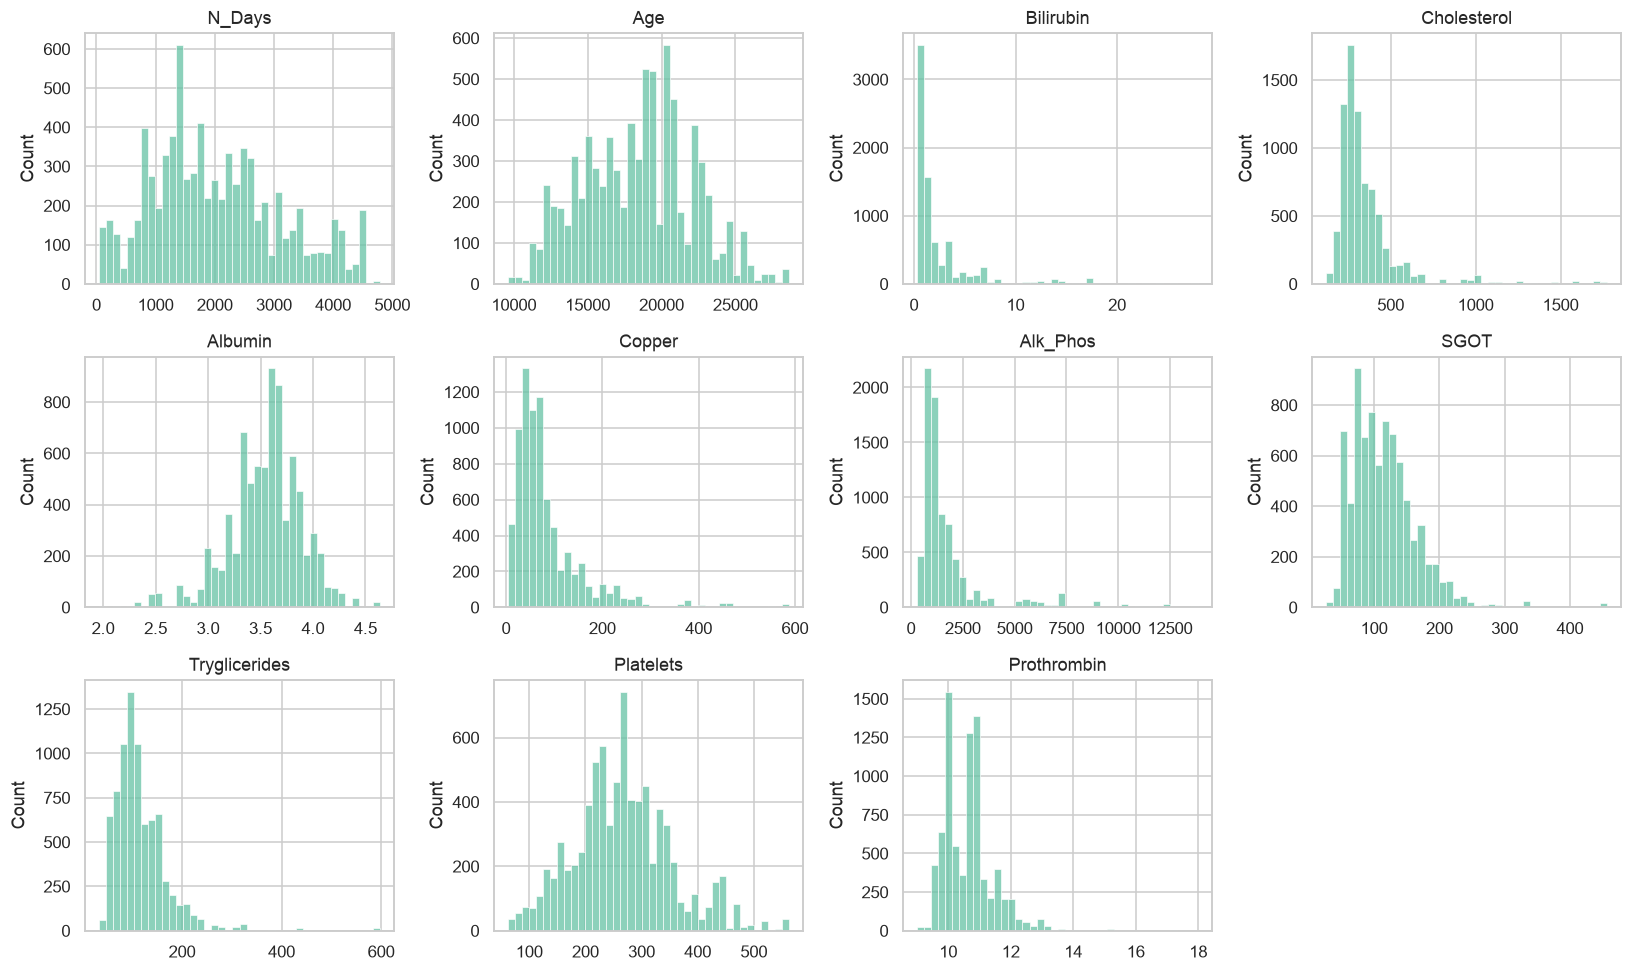

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(train[col], bins=40, ax=ax, color="#66c2a5")
    ax.set(title=col, xlabel="")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Вывод:**
- Гистограммы подтверждают скос шести лабораторных показателей.
- Видны резкие пики на отдельных значениях: Prothrombin — 10.6 и 11.0, Bilirubin — 0.6–0.8, у Platelets — ступеньки. Уникальных значений мало: 49 у Prothrombin и 111 у Bilirubin на 7905 строк.
- Это след генерации: строки «собраны» из 418 исходных пациентов, поэтому значения повторяются. Ошибки тут нет, но искать по таким признакам очень точные пороги бессмысленно.

### 4.2 Сырые и log1p-распределения

Проверяем, какие признаки после логарифмирования становятся ближе к симметричным.

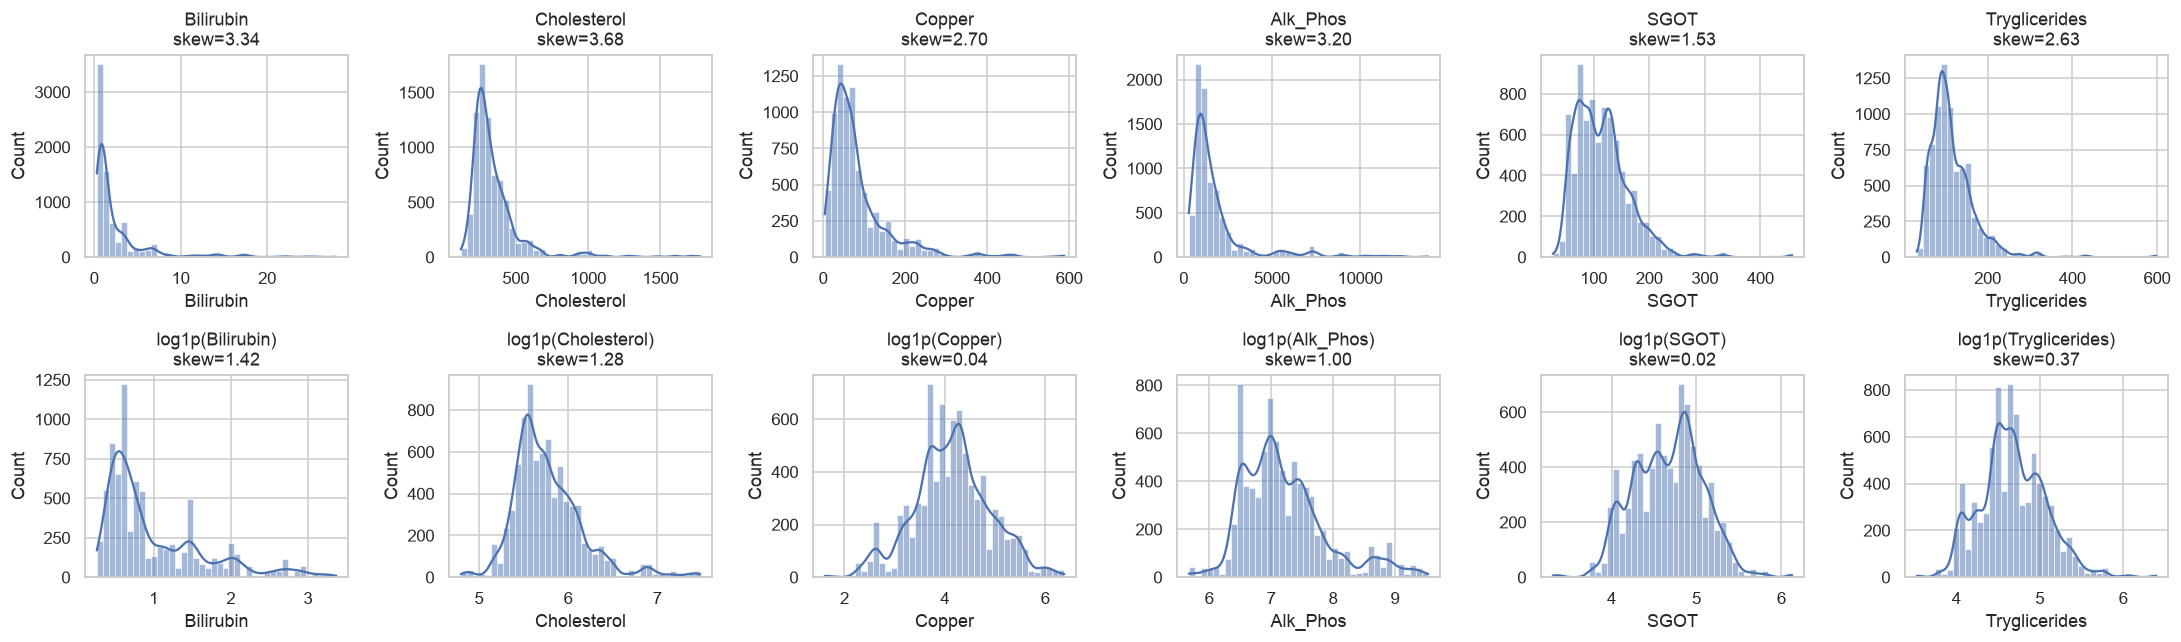

Prothrombin: skew 1.29 → после log1p 0.93


In [12]:
LOG_COLS = ["Bilirubin", "Cholesterol", "Copper", "Alk_Phos", "SGOT", "Tryglicerides"]

fig, axes = plt.subplots(2, len(LOG_COLS), figsize=(20, 6))
for i, c in enumerate(LOG_COLS):
    sns.histplot(train[c], bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{c}\nskew={train[c].skew():.2f}")

    sns.histplot(np.log1p(train[c]), bins=40, kde=True, ax=axes[1, i])
    axes[1, i].set_title(f"log1p({c})\nskew={np.log1p(train[c]).skew():.2f}")
plt.tight_layout()
plt.show()

print(f"Prothrombin: skew {train['Prothrombin'].skew():.2f} → после log1p {np.log1p(train['Prothrombin']).skew():.2f}")

**Вывод:**
- После `log1p` асимметрия резко падает: Copper 2.70 → 0.04, SGOT 1.53 → 0.02, Tryglicerides 2.63 → 0.37, Alk_Phos 3.20 → 1.00. У Bilirubin (3.34 → 1.42) и Cholesterol (3.68 → 1.28) хвост остаётся, но заметно короче.
- У Prothrombin логарифм даёт мало (1.29 → 0.93): значения лежат в узком диапазоне 9–18 с. Оставляем как есть.

### 4.3 Выбросы: правило IQR и z-оценка

Считаем выбросы двумя правилами: за «забором» 1.5 межквартильного размаха (IQR) и дальше трёх стандартных отклонений от среднего (|z| > 3).

In [13]:
def n_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outliers = pd.DataFrame({
    "за IQR": [n_outliers(train[c]) for c in num_cols],
    "доля, %": [round(n_outliers(train[c]) / len(train) * 100, 1) for c in num_cols],
    "|z| > 3": [int(((train[c] - train[c].mean()).abs() > 3 * train[c].std()).sum()) for c in num_cols],
    "максимум": [round(train[c].max(), 1) for c in num_cols],
}, index=num_cols)
outliers.sort_values("доля, %", ascending=False)

,за IQR,"доля, %",|z| > 3,максимум
Bilirubin,789,10.0,281,28.0
Alk_Phos,792,10.0,189,13862.4
Copper,655,8.3,151,588.0
Cholesterol,502,6.4,216,1775.0
Tryglicerides,267,3.4,113,598.0
Albumin,178,2.3,106,4.6
Prothrombin,173,2.2,113,18.0
SGOT,146,1.8,80,457.2
Platelets,114,1.4,41,563.0
Age,36,0.5,0,28650.0


**Вывод:**
- За границами IQR — 10 % строк по Bilirubin и Alk_Phos, 8.3 % по Copper, 6.4 % по Cholesterol.
- По правилу |z| > 3 выбросов в 2.5–4.5 раза меньше: 281 против 789 у Bilirubin. Причина — стандартное отклонение само раздуто хвостом, поэтому на скошенных данных z-оценка недосчитывает выбросы.
- Ни одну строку не удаляем: эти 10 % — не шум, а самые тяжёлые пациенты, и именно они важны для модели.

### 4.4 Визуализация выбросов

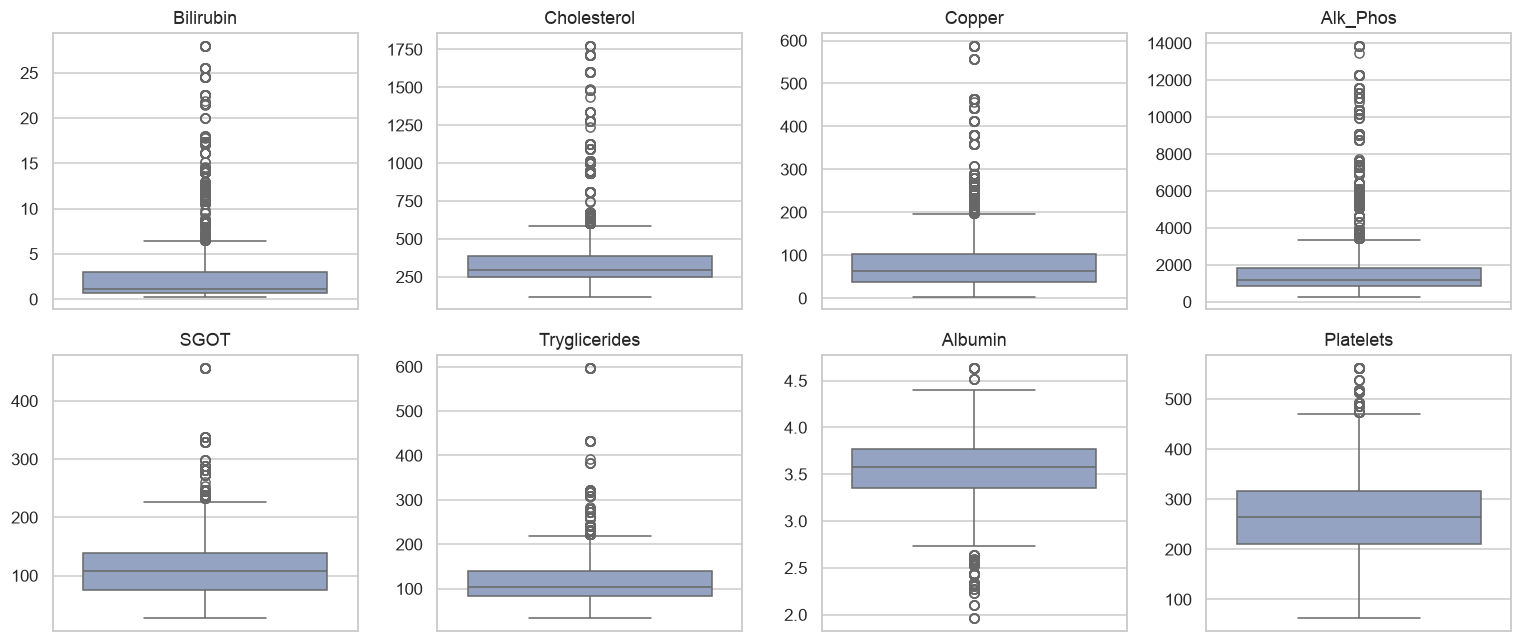

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, ["Bilirubin", "Cholesterol", "Copper", "Alk_Phos",
                               "SGOT", "Tryglicerides", "Albumin", "Platelets"]):
    sns.boxplot(y=train[col], ax=ax, color="#8da0cb")
    ax.set(title=col, ylabel="")
plt.tight_layout()
plt.show()

**Вывод:** ящики узкие, усы и точки вытянуты вправо; максимумы — Bilirubin 28, Alk_Phos 13 862, Cholesterol 1775. Значения правдоподобны (3.1), так что это тяжёлые случаи, а не битые данные. Линейной модели поможет `log1p`, деревьям преобразование не нужно.

## 5. Целевая переменная

### 5.1 Распределение Status

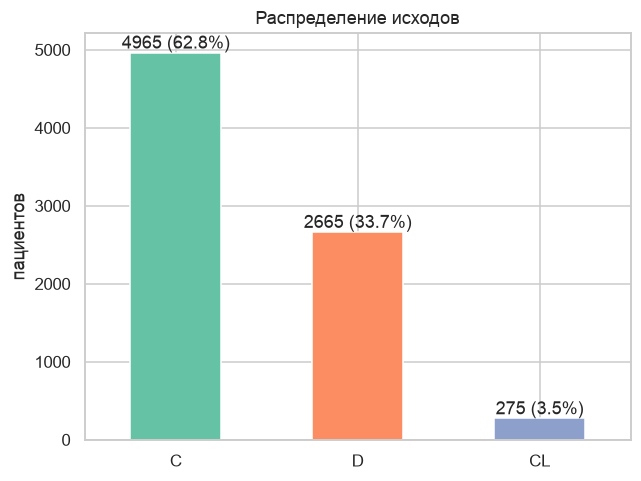

In [15]:
counts = train["Status"].value_counts()
ax = counts.plot(kind="bar", rot=0, color=["#66c2a5", "#fc8d62", "#8da0cb"])
ax.bar_label(ax.containers[0], labels=[f"{v} ({v / len(train):.1%})" for v in counts])
ax.set(title="Распределение исходов", ylabel="пациентов", xlabel="")
plt.show()

**Вывод:**
- C — 62.8 % (4965), D — 33.7 % (2665), CL — 3.5 % (275). CL встречается примерно в 18 раз реже C.
- Модель «всегда C» угадает 62.8 % и при этом будет бесполезна. Поэтому accuracy не подходит, ориентируемся на log loss — это метрика соревнования.
- В 5-фолдовой проверке на фолд придётся около 55 случаев CL, оценки по этому классу будут шумными.

### 5.2 Что такое log loss

Модель выдаёт не класс, а три вероятности, например C 0.55 / CL 0.05 / D 0.40. Штраф за одного пациента — минус логарифм вероятности, которую модель дала его настоящему исходу: `loss = −ln(p_истинного класса)`. Итоговый log loss — среднее по всем пациентам, чем меньше, тем лучше.

In [16]:
for p in [0.9, 0.7, 0.5, 0.337, 0.1, 0.035]:
    print(f"вероятность {p:5.3f} → штраф {-np.log(p):5.2f}")

prior = train["Status"].value_counts(normalize=True)
print()
print("доли классов:", prior.round(3).to_dict())
print("log loss константного предсказания:", round(-(prior * np.log(prior)).sum(), 3))

вероятность 0.900 → штраф  0.11
вероятность 0.700 → штраф  0.36
вероятность 0.500 → штраф  0.69
вероятность 0.337 → штраф  1.09
вероятность 0.100 → штраф  2.30
вероятность 0.035 → штраф  3.35

доли классов: {'C': 0.628, 'D': 0.337, 'CL': 0.035}
log loss константного предсказания: 0.776


**Вывод:**
- Уверенная ошибка стоит дорого: вероятность 0.01 на настоящий исход — штраф 4.61, столько же, сколько у десяти верных ответов с уверенностью 0.9 вместе.
- Если ничего не знать о пациенте и всем выдавать доли классов (0.628 / 0.035 / 0.337), log loss = 0.776. Это планка: всё, что ниже, — польза от признаков.
- Настоящий CL при вероятности 0.035 стоит 3.35 — один такой пациент весит как десяток лёгких. Редкий класс нельзя «бросить».

### 5.3 Фолды и стратификация

Кросс-валидация на 5 фолдах: делим 7905 строк на 5 частей по 1581, учим на четырёх, проверяем на пятой, повторяем пять раз и усредняем. Каждая строка ровно один раз попадает в проверку.

- **Стратификация** сохраняет доли классов в каждом фолде, иначе в одном фолде CL могло бы оказаться 40, в другом 70.
- **Утечка.** Всё, что учится на данных (заполнение пропусков, масштабирование, подбор параметров), настраивается только на обучающей части фолда. `log1p` — безопасное исключение: это фиксированная функция, подглядывать ей нечем.

Ниже — случайное разбиение с фиксированным seed; на нём считаются все log loss в разделе 6.

In [17]:
fold = np.random.default_rng(0).permutation(len(train)) % 5
fold_table = (train.assign(fold=fold)
              .groupby("fold")["Status"].value_counts()
              .unstack().fillna(0).astype(int))
fold_table["всего"] = fold_table.sum(axis=1)
fold_table

Status,C,CL,D,всего
fold,,,,
0,956,56,569,1581
1,995,52,534,1581
2,1034,56,491,1581
3,1017,55,509,1581
4,963,56,562,1581


**Вывод:** CL разложился ровно (52–56 на фолд). Для модели всё равно берём `StratifiedKFold` — так ровно будет при любом seed.

### 5.4 N_Days по исходам

`N_Days` — не клинический показатель, а срок наблюдения. Смотрим, как он связан с исходом.

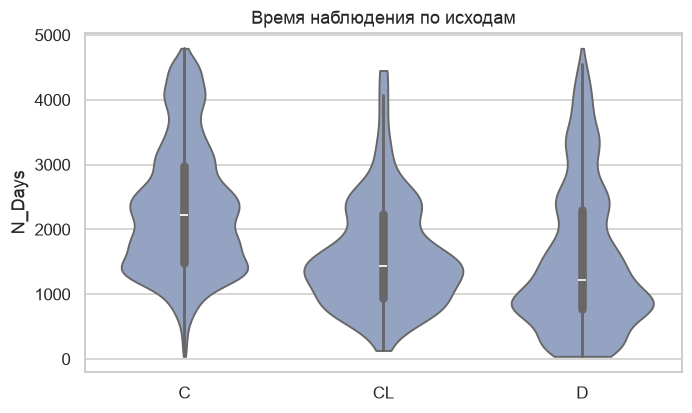

In [18]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=train, x="Status", y="N_Days", order=["C", "CL", "D"],
               color="#8da0cb", cut=0)
plt.title("Время наблюдения по исходам")
plt.xlabel("")
plt.show()

**Вывод:** медиана N_Days у C — 2216 дней, у CL — 1435, у D — 1216. У D есть и очень ранние события (10-й процентиль — 264 дня), и поздние (90-й — 3358).

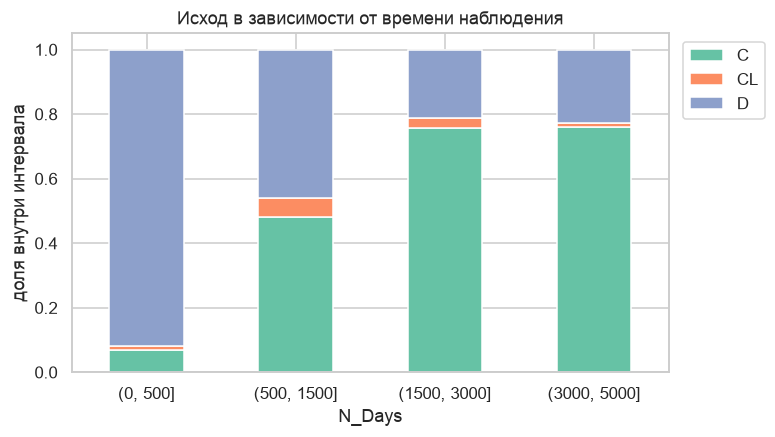

Status,C,CL,D
N_Days,,,
"(0, 500]",0.070,0.011,0.919
"(500, 1500]",0.482,0.059,0.459
"(1500, 3000]",0.758,0.031,0.211
"(3000, 5000]",0.760,0.011,0.229


In [19]:
buckets = pd.cut(train["N_Days"], [0, 500, 1500, 3000, 5000])
tab = pd.crosstab(buckets, train["Status"], normalize="index").round(3)

tab.plot(kind="bar", stacked=True, rot=0, figsize=(7, 4), color=sns.color_palette("Set2", 3))
plt.ylabel("доля внутри интервала")
plt.xlabel("N_Days")
plt.title("Исход в зависимости от времени наблюдения")
plt.legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

tab

**Вывод:**
- При N_Days < 500 умерли 91.9 %, при 500–1500 — 45.9 %, при 1500–3000 — 21.1 %, при 3000–5000 — 22.9 %. Из 66 человек с N_Days < 100 умерли 64.
- Это цензурирование: для D срок — время до смерти, для C — до конца исследования. Короткий срок почти всегда означает событие, длинный — что пациент дожил до конца.

In [20]:
target = pd.DataFrame({
    "C": (train["Status"] == "C").astype(int),
    "CL": (train["Status"] == "CL").astype(int),
    "D": (train["Status"] == "D").astype(int),
    "порядок C<CL<D": pd.Categorical(train["Status"], categories=["C", "CL", "D"]).codes,
    "N_Days": train["N_Days"],
})

corr_target = target.corr(method="spearman")["N_Days"].drop("N_Days").sort_values()
corr_target.round(3).to_frame("Спирмен с N_Days")

,Спирмен с N_Days
порядок C<CL<D,-0.372
D,-0.352
CL,-0.076
C,0.373


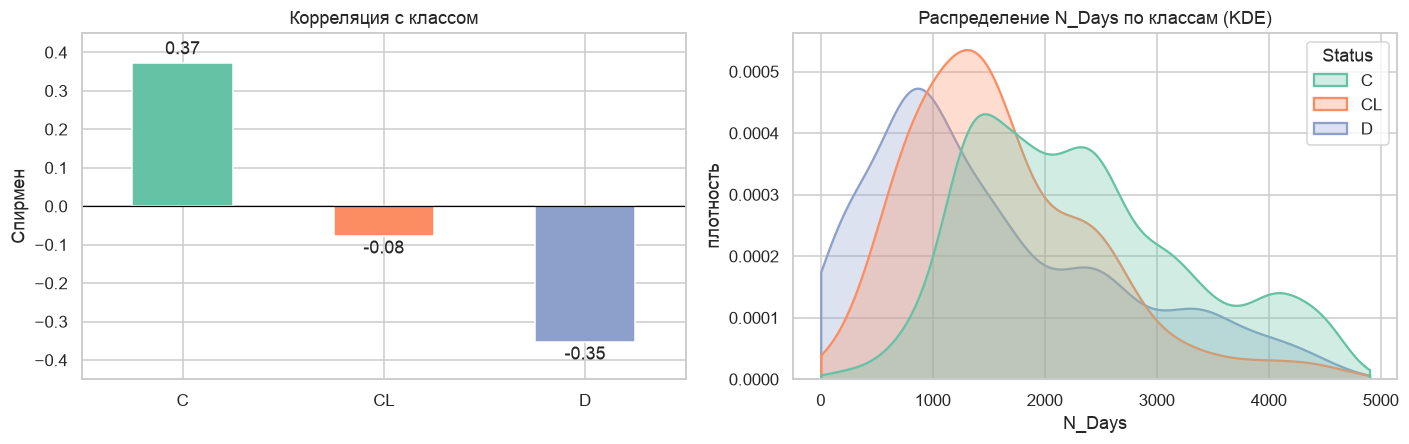

In [21]:
by_class = corr_target.reindex(["C", "CL", "D"])   # порядок как на графике цели
colors = {"C": "#66c2a5", "CL": "#fc8d62", "D": "#8da0cb"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

by_class.plot(kind="bar", rot=0, ax=ax1, color=list(colors.values()))
ax1.bar_label(ax1.containers[0], fmt="%.2f", padding=3)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set(title="Корреляция с классом", ylabel="Спирмен", xlabel="", ylim=(-0.45, 0.45))

# плотности нормированы внутри каждого класса, иначе CL не видно
sns.kdeplot(data=train, x="N_Days", hue="Status", hue_order=["C", "CL", "D"],
            palette=colors, common_norm=False, fill=True, alpha=0.3,
            linewidth=1.5, bw_adjust=1.2, clip=(0, 4900), ax=ax2)
ax2.set(title="Распределение N_Days по классам (KDE)", xlabel="N_Days", ylabel="плотность")

plt.tight_layout()
plt.show()

**Вывод:**
- Корреляция Спирмена N_Days с классом: C +0.37, D −0.35, CL −0.08. Длинный срок — это C, короткий — D.
- CL почти не связан со сроком: он и по срокам ближе к D, и малочислен, а у редкого класса коэффициент корреляции маленький даже при заметной разнице. Сравнивать классы по модулю коэффициента нельзя.
- Справа от 4000–4800 дней данных почти нет — это конец исследования. Форму кривой для CL не интерпретируем: за ней всего 275 точек.
- Итог: `N_Days` почти пересказывает метку, решение из 3.3 подтверждается.

## 6. Связь признаков с целевой переменной

### 6.1 Доля умерших по категориям

Для каждого уровня признака считаем долю смертей. Пунктир — общая доля D (33.7 %).

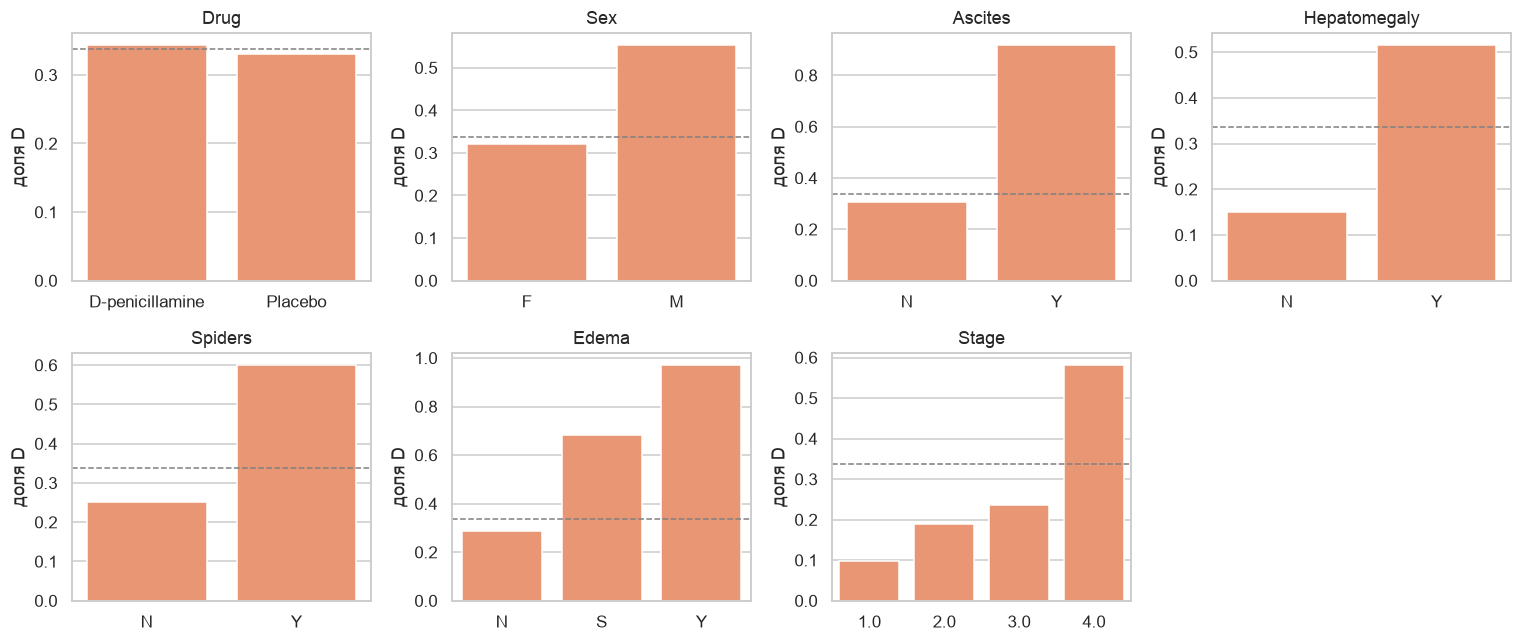

In [22]:
base = (train["Status"] == "D").mean()

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, cat_cols):
    rate = train.groupby(col)["Status"].apply(lambda s: (s == "D").mean())
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#fc8d62")
    ax.axhline(base, ls="--", color="grey", lw=1)
    ax.set(title=col, xlabel="", ylabel="доля D")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Вывод:**
- `Edema=Y` — 97.1 % смертей (345 человек), `Ascites=Y` — 91.8 % (380). Это самые жёсткие маркеры.
- `Hepatomegaly` и `Spiders` сдвигают долю D примерно на 35 процентных пунктов.
- `Stage` растёт монотонно: 9.8 % → 18.9 % → 23.5 % → 58.2 %, главный скачок — на 4-й стадии.
- `Drug` почти ничего не меняет: 34.4 % против 33.1 %.

### 6.2 Асцит и отёки вместе

Оба сильных признака — про жидкость и отёки. Проверяем, не описывают ли они одно и то же, и как асцит связан со стадией.

In [23]:
combo = train.groupby(["Ascites", "Edema"]).agg(
    n=("id", "size"),
    share_D=("Status", lambda s: (s == "D").mean()),
).round({"share_D": 3})
display(combo)
pd.crosstab(train["Ascites"], train["Stage"])

n  share_D
Ascites Edema               
N       N      7077    0.282
        S       347    0.648
        Y       101    0.941
Y       N        84    0.726
        S        52    0.923
        Y       244    0.984

Stage,1.0,2.0,3.0,4.0
Ascites,,,,
N,396,1632,3080,2417
Y,1,20,73,286


**Вывод:**
- Признаки не дублируют друг друга, а складываются: `Ascites=Y` и `Edema=Y` вместе — 244 человека и 98.4 % смертей, оба `N` — 7077 человек и 28.2 %.
- Доминирует `Edema`: при Edema=N асцит поднимает долю D с 28 % до 73 %, при Edema=Y — с 94 % до 98 %, потолок уже достигнут.
- 286 из 380 пациентов с асцитом — 4-я стадия: часть «силы» асцита на самом деле принадлежит стадии.
- Крайние группы — по 50–350 человек, оценки по ним нестабильны.

### 6.3 Статистическая проверка (хи-квадрат)

Проверяем, значима ли связь категориального признака со смертью. Если `p_value < 0.05`, связь значима.

In [24]:
rows = []
for c in cat_cols:
    tab = pd.crosstab(train[c], train["Status"] == "D")
    chi2, p, dof, _ = chi2_contingency(tab)
    rows.append({"признак": c, "chi2": round(chi2, 1), "p_value": p, "значим": p < 0.05})

pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)

,признак,chi2,p_value,значим
0,Hepatomegaly,1180.4,1.119426e-258,True
1,Stage,1132.9,2.710054e-245,True
2,Edema,915.1,1.916678e-199,True
3,Spiders,794.7,7.480961e-175,True
4,Ascites,600.9,1.086582e-132,True
5,Sex,127.5,1.422807e-29,True
6,Drug,1.5,2.270249e-01,False


**Вывод:** связь со смертью значима у всех признаков, кроме `Drug` (p = 0.23): препарат на исход не влияет, это совпадает с 6.1. При 7905 строках значимым выходит почти любой эффект, поэтому силу признаков сравниваем не по p-value, а по log loss (6.5).

### 6.4 Числовые признаки по исходам

In [25]:
train.groupby("Status")[num_cols].mean().T.round(2)

Status,C,CL,D
N_Days,2322.53,1610.11,1528.85
Age,17969.77,16230.60,19345.74
Bilirubin,1.36,2.90,4.86
Cholesterol,322.08,404.83,398.03
Albumin,3.62,3.55,3.41
Copper,61.49,102.91,123.69
Alk_Phos,1596.69,1823.01,2226.07
SGOT,102.83,127.44,135.21
Tryglicerides,107.41,122.56,129.38
Platelets,276.22,277.41,243.50


**Вывод:**
- Bilirubin растёт от C (1.36) к CL (2.90) и к D (4.86), Copper — 61 → 103 → 124. Albumin падает: 3.62 → 3.55 → 3.41.
- По биохимии CL — промежуточный класс: тяжелее C, легче D.
- Не всё монотонно: Cholesterol у D (398) выше, чем у C (322); Age у CL самый низкий (44.4 года), у D самый высокий (53.0). Линейная модель поймает основную часть сигнала, но не всю.

### 6.5 Сила каждого признака по отдельности

Каждый признак прогоняем через наивную модель: режем на 10 интервалов, внутри интервала прогноз — доли классов из обучающих фолдов, и считаем log loss на 5 фолдах (5.3). Это общая линейка: чем меньше log loss, тем больше признак знает об исходе сам по себе. Планка — 0.776 (5.2).

In [26]:
# измерительная линейка: наивная модель по одному признаку (10 интервалов, 5 фолдов)
def uni_logloss(col, n_bins=10):
    s = train[col]
    if s.nunique() <= 10:
        bins = np.asarray(pd.Categorical(s).codes)
    else:
        bins = np.asarray(pd.qcut(s, n_bins, labels=False, duplicates="drop"))
    y = pd.Categorical(train["Status"], categories=["C", "CL", "D"]).codes
    fold = np.random.default_rng(0).permutation(len(train)) % 5
    scores = []
    for k in range(5):
        tab = pd.crosstab(bins[fold != k], y[fold != k])
        probs = (tab + 1).div(tab.sum(axis=1) + 3, axis=0).to_numpy()
        p = probs[bins[fold == k]]
        scores.append(-np.log(p[np.arange((fold == k).sum()), y[fold == k]]).mean())
    return np.mean(scores)

strength = pd.Series({c: uni_logloss(c) for c in train.columns if c not in ("id", "Status")})
strength.sort_values().round(3).to_frame("log loss в одиночку")

,log loss в одиночку
Bilirubin,0.602
Copper,0.656
N_Days,0.658
Prothrombin,0.687
Hepatomegaly,0.694
Stage,0.702
SGOT,0.707
Edema,0.717
Spiders,0.725
Albumin,0.731


**Вывод:**
- Сильнейшие: Bilirubin — 0.602, Copper — 0.656, N_Days — 0.658, Prothrombin — 0.687. Все они измеряют тяжесть болезни.
- `Drug` — 0.776, ровно как константа: препарат не даёт ничего. `Sex` — 0.768.
- `Edema` (0.717) и `Ascites` (0.738) слабее биохимии, хотя доли смертей у них самые высокие. Они редкие (4–5 % пациентов), а внутри группы Y уточнять уже нечего. «Насколько страшно выглядит группа» и «сколько информации признак даёт о каждом пациенте» — разные вопросы.
- `N_Days` в тройке, но не первый: он силён потому, что содержит ответ.
- Разница в 0.01 — шум: порядок зависит от числа интервалов (при 40 интервалах у N_Days 0.644 вместо 0.658).

### 6.6 Как из признака получается log loss: разбор на Bilirubin

Без признаков вероятности — доли классов, одинаковые для всех (0.776). С признаком — доли классов **внутри интервала**, куда попал пациент. Ниже: сколько строк в интервале, доли классов, средний штраф внутри интервала (энтропия) и вклад интервала в общий log loss.

In [27]:
# разбор «линейки»: как один признак превращается в log loss
y = pd.Categorical(train["Status"], categories=["C", "CL", "D"]).codes
bins = pd.qcut(train["Bilirubin"], 10, labels=False, duplicates="drop")   # вышло 9 интервалов: часть границ совпала

tab = pd.crosstab(bins, y).rename(columns={0: "C", 1: "CL", 2: "D"})
tab.index.name = "интервал Bilirubin"
tab.columns.name = None
tab["n"] = tab.sum(axis=1)

probs = tab[["C", "CL", "D"]].div(tab["n"], axis=0)          # предсказание для любой строки этого интервала
entropy = -(probs * np.log(probs)).sum(axis=1)               # средний штраф внутри интервала
tab["энтропия"] = entropy.round(3)
tab["вклад"] = (tab["n"] / len(train) * entropy).round(4)
tab

,C,CL,D,n,энтропия,вклад
интервал Bilirubin,,,,,,
0,1475,18,138,1631,0.350,0.0721
1,1076,10,180,1266,0.454,0.0727
2,518,5,85,608,0.451,0.0347
3,566,26,143,735,0.638,0.0593
4,365,25,144,534,0.757,0.0511
5,404,38,362,804,0.849,0.0864
6,241,87,529,857,0.887,0.0961
7,183,49,449,681,0.817,0.0704
8,137,17,635,789,0.561,0.0560


In [28]:
prior = np.bincount(y) / len(y)
h_y = -(prior * np.log(prior)).sum()                         # неопределённость без признаков
h_cond = (tab["n"] / len(train) * entropy).sum()             # неопределённость при знании интервала

print(f"H(Y) без признаков : {h_y:.3f}")
print(f"H(Y | интервал)    : {h_cond:.3f}")
print(f"выигрыш            : {h_y - h_cond:.3f}")

H(Y) без признаков : 0.776
H(Y | интервал)    : 0.599
выигрыш            : 0.177


**Вывод:** сумма «энтропия × доля строк» даёт 0.599; разница с 0.776 (0.177) — столько информации об исходе несёт один Bilirubin. В кросс-валидации выходит 0.602, а не 0.599: там таблица строится на других фолдах, без подглядывания в ответы, поэтому оценка чуть хуже и честнее.

### 6.7 Пары признаков

Сильный в одиночку признак может почти ничего не добавить, если дублирует другой. Проверяем той же линейкой пары.

In [29]:
# та же линейка, но по паре признаков (6 интервалов на признак, поэтому числа чуть отличаются от таблицы с 10)
def naive_logloss(cols, n_bins=6):
    keys = []
    for c in cols:
        if train[c].nunique() <= 10:          # категориальные (Hepatomegaly) кодируем, числовые режем на интервалы
            keys.append(np.asarray(pd.Categorical(train[c]).codes))
        else:
            keys.append(np.asarray(pd.qcut(train[c], n_bins, labels=False, duplicates="drop")))
    cell = keys[0]
    for k in keys[1:]:
        cell = cell * (k.max() + 1) + k
    y = pd.Categorical(train["Status"], categories=["C", "CL", "D"]).codes
    fold = np.random.default_rng(0).permutation(len(train)) % 5
    scores = []
    for k in range(5):
        tab = pd.crosstab(cell[fold != k], y[fold != k])
        p = (tab + 1).div(tab.sum(axis=1) + 3, axis=0).to_numpy()[cell[fold == k]]
        scores.append(-np.log(p[np.arange((fold == k).sum()), y[fold == k]]).mean())
    return round(np.mean(scores), 3)

for cols in [["Bilirubin"], ["Bilirubin", "Copper"], ["Bilirubin", "Hepatomegaly"]]:
    print(f"{' + '.join(cols):24s} {naive_logloss(cols)}")

Bilirubin                0.604
Bilirubin + Copper       0.586
Bilirubin + Hepatomegaly 0.581


**Вывод:** Copper добавляет к Bilirubin 0.018 (0.604 → 0.586), Hepatomegaly — 0.023 (0.604 → 0.581). В одиночку Copper сильнее (0.656 против 0.694), но он дублирует Bilirubin (корреляция 0.59), а Hepatomegaly приносит свою информацию.

## 7. Корреляции и мультиколлинеарность

### 7.1 Корреляция Спирмена

Берём Спирмена, а не Пирсона: распределения скошены, а Спирмен ловит монотонную связь и не боится хвостов.

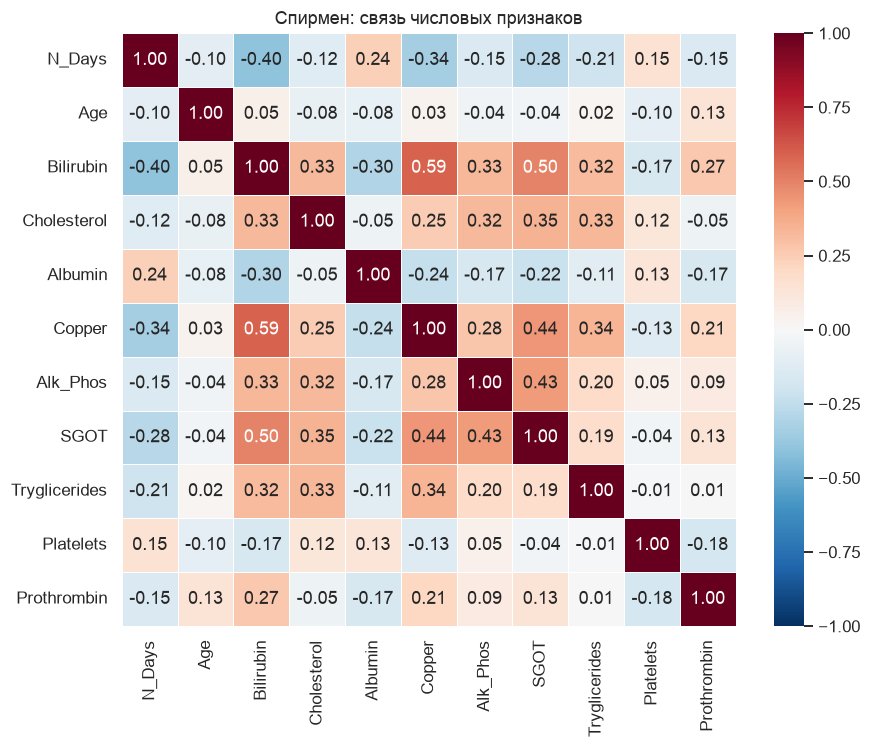

In [30]:
corr = train[num_cols].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Спирмен: связь числовых признаков")
plt.show()

**Вывод:**
- Сильнее всего связаны Bilirubin–Copper (0.59), Bilirubin–SGOT (0.50), SGOT–Alk_Phos (0.43). Albumin связан со всеми маркерами тяжести отрицательно (до −0.30 с Bilirubin).
- Это один общий фактор — тяжесть поражения печени: Bilirubin, Copper, SGOT и Alk_Phos растут вместе, Albumin и Platelets ведут себя как «запас прочности».
- Мультиколлинеарность заметная, но не критичная (0.59 — ещё не одна и та же переменная). Линейной модели поможет регуляризация, бустинг справится сам. Признаки не выбрасываем.

### 7.2 Bilirubin и Albumin вместе

Цвет ячейки — доля умерших в ней. Ячейки, где меньше 10 человек, скрыты. Ось X логарифмическая, потому что Bilirubin скошен.

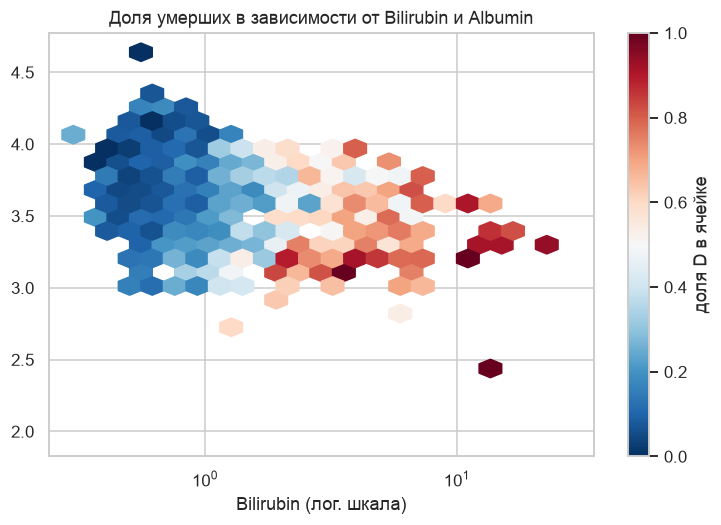

In [31]:
plt.figure(figsize=(8, 5))
hb = plt.hexbin(train["Bilirubin"], train["Albumin"], C=(train["Status"] == "D"),
                gridsize=(22, 14), cmap="RdBu_r", vmin=0, vmax=1,
                reduce_C_function=np.mean, mincnt=10, xscale="log")
plt.colorbar(hb, label="доля D в ячейке")
plt.title("Доля умерших в зависимости от Bilirubin и Albumin")
plt.xlabel("Bilirubin (лог. шкала)")
plt.show()

**Вывод:**
- Синяя зона (доля D < 20 %) — низкий Bilirubin при Albumin выше 3.4; по диагонали цвет плавно переходит в красный (> 80 %) — высокий Bilirubin при низком Albumin. Резкой границы нет.
- Значит, модель должна выдавать вероятность, а не жёсткую метку. Отношение Bilirubin/Albumin — осмысленный кандидат в новые признаки: оно измеряет положение вдоль этой диагонали.
- CL здесь не виден: цвет считает только D.

### 7.3 Как меняются анализы со стадией

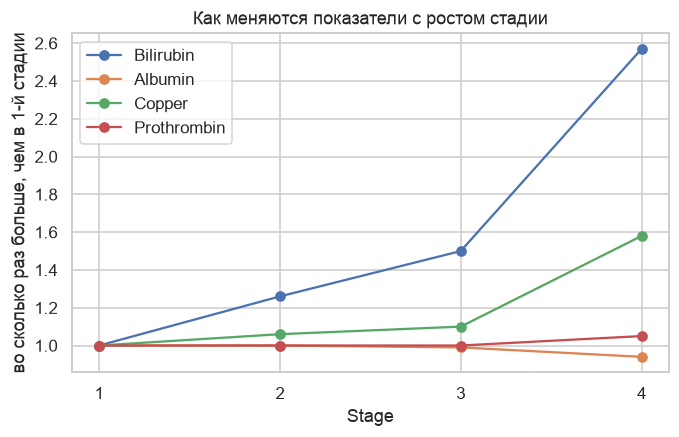

In [32]:
stage_means = train.groupby("Stage")[["Bilirubin", "Albumin", "Copper", "Prothrombin"]].mean()
rel = (stage_means / stage_means.iloc[0]).round(2)

rel.plot(marker="o", figsize=(7, 4))
plt.xticks([1, 2, 3, 4])
plt.xlabel("Stage")
plt.ylabel("во сколько раз больше, чем в 1-й стадии")
plt.title("Как меняются показатели с ростом стадии")
plt.show()

**Вывод:**
- От 1-й к 4-й стадии Bilirubin растёт в 2.6 раза, Copper — в 1.6, Albumin падает до 0.94, Prothrombin почти не меняется (1.05). Главный скачок — между 3-й и 4-й стадиями.
- `Stage` — сводка тяжести, частично пересказывает биохимию, но у неё есть порог на 4-й стадии. Деревья его найдут легко, линейной модели поможет кодировать стадии отдельными индикаторами или флаг `Stage=4`.

## 8. Одинаковы ли train и test

Набор разрезан по порядку строк (1.5). Если test отличается по распределениям, качество на train не перенесётся.

In [33]:
drift = pd.DataFrame({
    "train": train[num_cols].mean(),
    "test": test[num_cols].mean(),
})
drift["сдвиг, SD"] = (drift["test"] - drift["train"]) / train[num_cols].std()
drift.round(2)

,train,test,"сдвиг, SD"
N_Days,2030.17,2038.70,0.01
Age,18373.15,18497.76,0.03
Bilirubin,2.59,2.60,0.00
Cholesterol,350.56,352.49,0.01
Albumin,3.55,3.54,-0.03
Copper,83.90,84.70,0.01
Alk_Phos,1816.75,1811.23,-0.00
SGOT,114.60,113.59,-0.02
Tryglicerides,115.34,115.29,-0.00
Platelets,265.23,264.02,-0.01


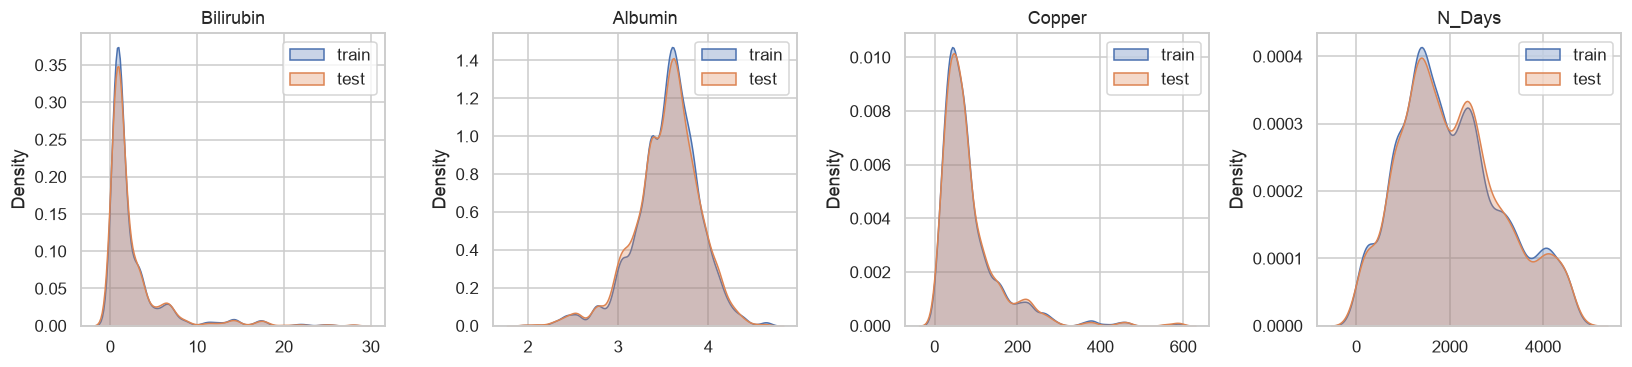

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes, ["Bilirubin", "Albumin", "Copper", "N_Days"]):
    sns.kdeplot(data=train, x=col, ax=ax, label="train", fill=True, alpha=0.3)
    sns.kdeplot(data=test, x=col, ax=ax, label="test", fill=True, alpha=0.3)
    ax.set(title=col, xlabel="")
    ax.legend()
plt.tight_layout()
plt.show()

In [35]:
for col in ["Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage", "Drug"]:
    print(f"{col:13s} train {train[col].value_counts(normalize=True).round(3).to_dict()}")
    print(f"{'':13s} test  {test[col].value_counts(normalize=True).round(3).to_dict()}")

Sex           train {'F': 0.928, 'M': 0.072}
              test  {'F': 0.925, 'M': 0.075}
Ascites       train {'N': 0.952, 'Y': 0.048}
              test  {'N': 0.954, 'Y': 0.046}
Hepatomegaly  train {'Y': 0.511, 'N': 0.489}
              test  {'Y': 0.518, 'N': 0.482}
Spiders       train {'N': 0.755, 'Y': 0.245}
              test  {'N': 0.754, 'Y': 0.246}
Edema         train {'N': 0.906, 'S': 0.05, 'Y': 0.044}
              test  {'N': 0.908, 'S': 0.05, 'Y': 0.042}
Stage         train {3.0: 0.399, 4.0: 0.342, 2.0: 0.209, 1.0: 0.05}
              test  {3.0: 0.403, 4.0: 0.34, 2.0: 0.212, 1.0: 0.046}
Drug          train {'Placebo': 0.507, 'D-penicillamine': 0.493}
              test  {'Placebo': 0.511, 'D-penicillamine': 0.489}


In [36]:
# одни и те же данные пациента могут встретиться в обоих наборах, если различается только срок наблюдения
feat = [c for c in train.columns if c not in ("id", "Status", "N_Days")]
key_train = train[feat].astype(str).agg("|".join, axis=1)
key_test = test[feat].astype(str).agg("|".join, axis=1)
print("строк test, совпадающих с train по всем признакам, кроме N_Days:",
      key_test.isin(set(key_train)).sum())

строк test, совпадающих с train по всем признакам, кроме N_Days: 5


**Вывод:**
- Максимальный сдвиг средних — около 0.03 стандартного отклонения (Age), у остальных меньше 0.02. Кривые совпадают, доли категорий тоже: женщин 92.8 % в train и 92.5 % в test, Stage=4 — 34.2 % и 34.0 %.
- Это один сгенерированный пул, разрезанный по порядку строк, и порядок не связан с признаками. Проверка на train осмысленна, сдвига между наборами нет.
- 5 строк test совпадают с train по всем признакам, кроме `N_Days`. На 5271 строку это ни на что не влияет.

## 9. Выводы

**О данных.** Синтетика по мотивам UCI Cirrhosis: 418 исходных пациентов «размножены» до 13 176 строк. Таблица чистая — нет пропусков, дублей и невозможных значений, — но есть следы генерации: 93 % женщин, повторяющиеся значения, препарат без эффекта.

**Что показал анализ:**
1. **`N_Days` — часть метки, а не признак пациента.** При сроке < 500 дней умирают 91.9 %, при 1500+ — около 22 %. В одиночку он даёт log loss 0.658, но Bilirubin сильнее (0.602). В момент прогноза срок неизвестен, поэтому в модель его не берём.
2. **Сигнал в данных один — тяжесть болезни печени.** Bilirubin, Copper, SGOT, Alk_Phos и Stage растут вместе (0.59, 0.50, 0.43), Albumin и Platelets — в обратную сторону. Независимого «второго» сигнала нет.
3. **Edema и Ascites — маркеры терминальной стадии.** Edema=Y — 97.1 % смертей (345 человек), Ascites=Y — 91.8 % (380). Но они редкие и почти детерминированы, поэтому как признаки слабее биохимии (0.717 и 0.738 против 0.602 у Bilirubin).
4. **У CL нет своей области.** По биохимии он между C и D (Bilirubin 2.90 против 1.36 и 4.86) и в плоскости Bilirubin × Albumin отдельного облака не образует. Основные ошибки модели будут на CL и на размытой границе C/D.
5. **Выбросы — это тяжёлые пациенты.** Шесть показателей с длинным правым хвостом (асимметрия до 3.7), 10 % значений за IQR, но все значения физиологичны — удалять нечего.
6. **Препарат не работает.** `Drug` меняет долю D на 1 п. п. (34.4 % против 33.1 %), хи-квадрат незначим, log loss равен константе. Это свойство синтетики.
7. **train и test однородны.** Сдвиг средних не больше 0.03 SD, доли категорий совпадают.

**Что это значит для модели:**
- Метрика — log loss, планка 0.776.
- `log1p` для Bilirubin, Cholesterol, Copper, Alk_Phos, SGOT, Tryglicerides; `Age` в годы; `Stage` и `Edema` — порядковые.
- Выбросы не удаляем.
- Стратифицированная валидация обязательна (CL — 3.5 %, 275 человек), повторяющиеся профили держим в одной группе.
- `N_Days` и `id` в признаки не идут.
- Кандидаты в новые признаки: Bilirubin/Albumin, Copper/Albumin, флаг `Stage=4`.

**Чего анализ не показывает:**
- Причинности: «Edema связан со смертью» не значит «отёк вызывает смерть».
- Переносимости на реальных пациентов: test — тот же синтетический пул.
- Поведения на редких комбинациях: группы по 50–100 человек слишком малы для уверенных выводов.